# PR8: Decision Tree vs Naive Bayes

**Aim:** Train both classifiers on the Breast Cancer dataset, compare the metrics and pick the best model.

| | Decision Tree | Naive Bayes |
|---|---|---|
| Idea | Asks yes/no questions on features (if-else tree) | Uses Bayes theorem, assumes features are independent |
| Needs scaling? | No | No |
| Risk | Overfitting | The independence assumption is rarely true |

## 1. Load and split

In [8]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split

data = load_breast_cancer(as_frame=True)
df = data.frame

X = df.drop(columns=["target"])
y = df["target"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(X_train.shape, X_test.shape)

(455, 30) (114, 30)


## 2. Decision Tree

In [9]:
from sklearn.tree import DecisionTreeClassifier

tree = DecisionTreeClassifier(random_state=42)
tree.fit(X_train, y_train)
pred_tree = tree.predict(X_test)

## 3. Naive Bayes (Gaussian, because features are continuous)

In [10]:
from sklearn.naive_bayes import GaussianNB

nb = GaussianNB()
nb.fit(X_train, y_train)
pred_nb = nb.predict(X_test)

## 4. Compare using metrics

In [11]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

def get_scores(y_true, y_pred):
    return [accuracy_score(y_true, y_pred),
            precision_score(y_true, y_pred),
            recall_score(y_true, y_pred),
            f1_score(y_true, y_pred)]

result = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1-score"],
    "Decision Tree": get_scores(y_test, pred_tree),
    "Naive Bayes": get_scores(y_test, pred_nb),
})
print(result.round(4))

      Metric  Decision Tree  Naive Bayes
0   Accuracy         0.9474       0.9737
1  Precision         0.9577       0.9595
2     Recall         0.9577       1.0000
3   F1-score         0.9577       0.9793


In [12]:
print("Decision Tree confusion matrix:")
print(confusion_matrix(y_test, pred_tree))
print()
print("Naive Bayes confusion matrix:")
print(confusion_matrix(y_test, pred_nb))

Decision Tree confusion matrix:
[[40  3]
 [ 3 68]]

Naive Bayes confusion matrix:
[[40  3]
 [ 0 71]]


## 5. Look at the tree (top 3 levels)

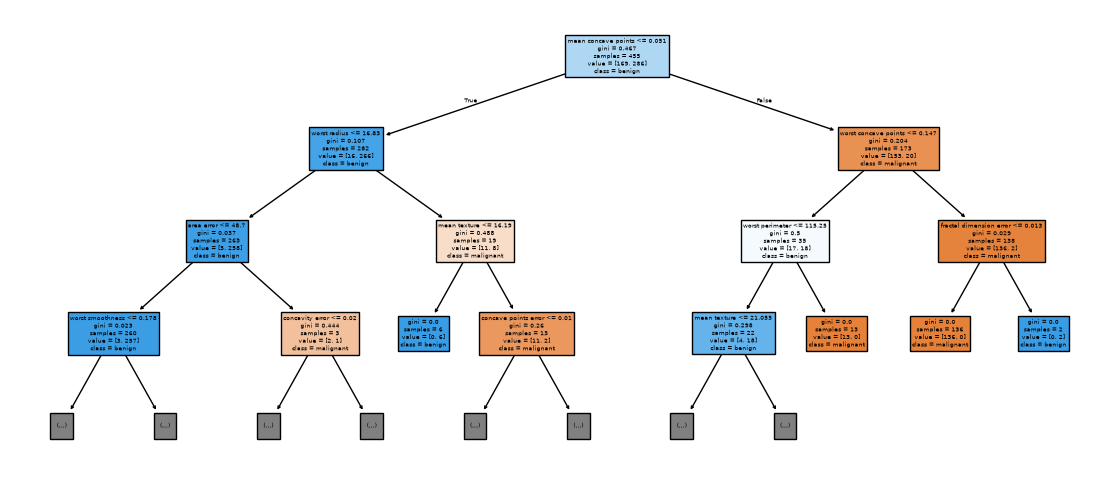

In [13]:
from sklearn.tree import plot_tree

plt.figure(figsize=(14, 6))
plot_tree(tree, max_depth=3, feature_names=X.columns, class_names=["malignant", "benign"], filled=True)
plt.show()

## 6. Pick the best model

In [14]:
if f1_score(y_test, pred_tree) > f1_score(y_test, pred_nb):
    print("Best model: Decision Tree")
else:
    print("Best model: Naive Bayes")

Best model: Naive Bayes


## Viva points

- Decision Tree splits using **Gini impurity** or **entropy** (information gain).
- A fully grown tree overfits. Control it with `max_depth`.
- Naive Bayes: P(class | features) is proportional to P(class) * P(feature1|class) * P(feature2|class) ...
- "Naive" because it assumes all features are independent of each other.
- Choose the model by the metrics on the **test** set (look at F1 and Recall).